# HSE 2024: Mathematical Methods for Data Analysis

## Homework 4

**Warning 1**: You have 10 days for this assignemnt.  **it is better to start early (!)**

**Warning 2**: it is critical to describe and explain what you are doing and why, use markdown cells


### Contents

#### Decision Trees - 7 points
* [Task 1](#task1) (0.5 points)
* [Task 2](#task2) (0.5 points)
* [Task 3](#task3) (2 points)
* [Task 4](#task4) (0.5 points)
* [Task 5](#task5) (0.5 points)
* [Task 6](#task6) (2 points)
* [Task 7](#task7) (0.5 points)
* [Task 8](#task8) (0.5 points)

#### Ensembles - 3 points
* [Task 1](#task2_1) (1 point)
* [Task 2](#task2_2) (0.7 points)
* [Task 3](#task2_3) (0.5 points)
* [Task 4](#task2_4) (0.7 points)
* [Task 5](#task2_5) (0.1 points)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams['figure.figsize'] = (11, 5)
%matplotlib inline

# Part 1. Decision Tree Regressor

In this task you will be implementing decision tree for the regression by hand.

### Task 1 <a id="task1"></a> (0.5 points)

Here you should implement the function `H()` which calculates impurity criterion. We will be training regression tree, and will take mean absolute deviation as impurity criterion.

* You cannot use loops
* If `y` is empty, the function should return 0

In [ ]:
def H(y):
    """
    Calculate impurity criterion

    Parameters
    ----------
    y : np.array
        array of objects target values in the node

    Returns
    -------
    H(R) : float
        Impurity in the node (measuread by variance)
    """
    if len(y) != 0 :
        mean_y = np.mean(y)
        return np.mean(np.abs(y - mean_y))  # Calculate mean absolute deviation
    return 0.0

In [ ]:
# Test the function
assert np.allclose(H(np.array([4, 2, 2, 2])), 0.75)
assert np.allclose(H(np.array([])), 0.0)

### Task 2 <a id="task2"></a>  (0.5 points)

To find the best split in the node we need to calculate the cost function. Denote:
- `R` all the object in the node
- `j` index of the feature selected for the split
- `t` threshold
- `R_l` and `R_r` objects in the left and right child nodes correspondingly

We get the following cost function:

$$
Q(R, j, t) =\frac{|R_\ell|}{|R|}H(R_\ell) + \frac{|R_r|}{|R|}H(R_r) \to \min_{j, t},
$$

Implement the function `Q`, which should calculate value of the cost function for a given feature and threshold.

In [ ]:
def Q(X, y, j, t):
    """
    Calculate cost function
    Parameters
    ----------
    X : ndarray
        array of objects in the node
    y : ndarray
        array of target values in the node
    j : int
        feature index (column in X)
    t : float
        threshold

    Returns
    -------
    Q : float
        Value of the cost function
    """
    left_mask = X[:, j] <= t
    right_mask = X[:, j] > t
    R_l = y[left_mask]
    R_r = y[right_mask]
    size_R = len(y)
    size_R_l = len(R_l)
    size_R_r = len(R_r)
    H_R_l = H(R_l)
    H_R_r = H(R_r)
    if size_R == 0:
        return 0.0
    Q_value = (size_R_l / size_R) * H_R_l + (size_R_r / size_R) * H_R_r
    return Q_value

### Task 3 <a id="task3"></a>  (2 points)

Now, let's implement `MyDecisionTreeRegressor` class. More specifically, you need to implement the following methods:

- `best_split`
- `grow_tree`
- `get_prediction`

Also, please add `min_samples_leaf` parameter to your class

Read docstrings for more details. Do not forget to use function `Q` implemented above, when finding the `best_split`

In [ ]:
class Node(object):
    """
    Class for a decision tree node.

    Parameters
    ----------
    right : Node() or None
        Right child
    left : Node() or None
        Left child
    threshold: float

    column: int

    depth: int

    prediction: float
        prediction of the target value in the node
        (average values calculated on a train dataset)
    is_terminal:bool
        indicates whether it is a terminal node (leaf) or not
    """
    def __init__(self):
        self.right = None
        self.left = None
        self.threshold = None
        self.column = None
        self.depth = None
        self.is_terminal = False
        self.prediction = None

    def __repr__(self):
        if self.is_terminal:
            node_desc = 'Pred: {:.2f}'.format(self.prediction)
        else:
            node_desc = 'Col {}, t {:.2f}, Pred: {:.2f}'. \
            format(self.column, self.threshold, self.prediction)
        return node_desc

In [ ]:
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted

class MyDecisionTreeRegressor(RegressorMixin, BaseEstimator):
    """
    Class for a Decision Tree Regressor.

    Parameters
    ----------
    max_depth : int
        Max depth of a decision tree.
    min_samples_split : int
        Minimal number of samples (objects) in a node to make a split.
    min_samples_leaf: int
        Minimum number of samples (objects) in left and right branches after splitting the current node
    """
    def __init__(self, max_depth=3, min_samples_split=2, min_samples_leaf=1):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf

    def best_split(self, X, y):
        """
        Find the best split in terms of Q of data in a given decision tree node.
        Try all features and thresholds.

        Parameters
        ----------
        X : ndarray, shape (n_objects, n_features)
            Objects in the parent node
        y : ndarray, shape (n_objects, )
            1D array with the object labels.

        Returns
        -------
        best_split_column : int
            Index of the best split column
        best_threshold : float
            The best split condition.
        X_left : ndarray, shape (n_objects_l, n_features)
            Objects in the left child
        y_left : ndarray, shape (n_objects_l, )
            Objects labels in the left child.
        X_right : ndarray, shape (n_objects_r, n_features)
            Objects in the right child
        y_right : ndarray, shape (n_objects_r, )
            Objects labels in the right child.
        """

        # To store best split parameters
        best_split_column = None
        best_threshold = None
        best_information_gain = -999
        # without splitting
        impurity = H(y)
        n_samples, n_features = X.shape
        for split_column in range(X.shape[1]):

            # Select values of the column
            x_col = X[:, split_column]

            # For each value in the column ...
            for i_x in range(0, len(x_col)):

                # Take the value as a threshold for a split
                threshold = x_col[i_x]

                # Make the split into right and left childs
                x_left = X[x_col <= threshold, :]
                x_right =X[x_col > threshold, :]
                y_right = y[x_col > threshold]
                y_left = y[x_col <= threshold]

                if len(y_right) == 0 or len(y_left) == 0:
                    continue

                # Calculate impurity for each child
                impurity_left = Q(x_left, y_left, split_column, i_x)
                impurity_right = Q(x_right, y_right, split_column, i_x)
                impurity = Q(X, y, split_column, i_x)
                # impurity_right = 0.6 (example)

                # Calculate information gain of the split
                information_gain = impurity
                information_gain -= impurity_left * len(y_left) / len(y)
                information_gain -= impurity_right * len(y_right) / len(y)
                # information_gain = 0.2 (example)

                # Is this information_gain the best?
                if information_gain > best_information_gain:
                    best_split_column = split_column
                    best_threshold = threshold
                    best_information_gain = information_gain

        # If no split available
        if best_information_gain == -999:
            return None, None, None, None, None, None
        x_col = X[:, best_split_column]
        X_left = X[x_col <= best_threshold, :]
        y_left = y[x_col <= best_threshold]
        X_right = X[x_col > best_threshold, :]
        y_right = y[x_col > best_threshold]

        return best_split_column, best_threshold, X_left, y_left, X_right, y_right

    def is_terminal(self, node, y):
        """
        Check terminality conditions based on `max_depth`,
        `min_samples_split` parameters for a given node.

        Parameters
        ----------
        node : Node,

        y : ndarray, shape (n_objects, )
            Object labels.

        Returns
        -------
        Is_termial : bool
            If True, node is terminal
        """
        if node.depth >= self.max_depth:
            return True
        if len(y) < self.min_samples_split:
            return True
        return False

    def grow_tree(self, node, X, y):
        """
        Reccurently grow the tree from the `node` using a `X` and `y` as a dataset:
         - check terminality conditions
         - find best split if node is not terminal
         - add child nodes to the node
         - call the function recursively for the added child nodes

        Parameters
        ----------
        node : Node() object
            Current node of the decision tree.
        X : ndarray, shape (n_objects, n_features)
            Objects
        y : ndarray, shape (n_objects)
            Labels
        """

        if self.is_terminal(node, y):
            node.is_terminal =True
            node.prediction = np.mean(y)
            return

        best_split_column, best_threshold, X_left, y_left, X_right, y_right = self.best_split(X, y)

        if best_split_column is None:
            node.is_terminal = True
            node.prediction = np.mean(y)  # Store mean prediction if no valid split found
            return
        node.column = best_split_column
        node.threshold = best_threshold
        node.left = Node()
        node.right = Node()
        node.left.depth = node.depth + 1 if node.depth is not None else 0
        node.right.depth = node.depth + 1 if node.depth is not None else 0

        # Recursively grow left and right child nodes
        self.grow_tree(node.left, X_left, y_left)
        self.grow_tree(node.right, X_right, y_right)

    def fit(self, X, y):
        """
        Fit the Decision Tree Regressor.

        Parameters
        ----------
        X : ndarray, shape (n_samples, n_features)
            The input samples.
        y : ndarray, shape (n_samples,) or (n_samples, n_outputs)
            The target values.
        Returns
        -------
        self : object
            Returns self.
        """
        X, y = check_X_y(X, y, accept_sparse=False)
        self.is_fitted_ = True
        self.n_features_in_ = X.shape[1]
        # Initialize the tree (root node)
        self.tree_ = Node()
        self.tree_.depth = 0
        self.tree_.prediction = np.mean(y)

        # Grow the tree
        self.grow_tree(self.tree_, X, y)
        return self

    def get_prediction(self, node, x):
        """
        Get prediction for an object `x`
            - Return prediction of the `node` if it is terminal
            - Otherwise, recursively call the function to get
            predictions of the proper child

        Parameters
        ----------
        node : Node() object
            Current node of the decision tree.
        x : ndarray, shape (n_features,)
            Array of feature values of one object.
        Returns
        -------
        y_pred : float
            Prediction for an object x
        """
        if node.is_terminal:
            return node.prediction
        if x[node.column] > node.threshold:
            return self.get_prediction(node.right, x)
        else:
            return self.get_prediction(node.left, x)

    def predict(self, X):
        """
        Get prediction for each object in X

        Parameters
        ----------
        X : ndarray, shape (n_samples, n_features)
            The input samples.
        Returns
        -------
        y : ndarray, shape (n_samples,)
            Returns predictions.
        """
        # Check input and that `fit` had been called
        X = check_array(X, accept_sparse=False)
        check_is_fitted(self, 'is_fitted_')

        # Get predictions
        y_predicted = []
        for x in X:
            y_curr = self.get_prediction(self.tree_, x)
            y_predicted.append(y_curr)
        return np.array(y_predicted)

    def get_params(self, deep=True):
        """
        Returns class parameters.

        Parameters
        ----------
        deep : boolean
            If True, will return the parameters for this estimator and contained subobjects that are estimators.

        Returns
        -------
        params : dict
            Parameters of the class.
        """

        params = {'max_depth': self.max_depth,
                  'min_samples_leaf': self.min_samples_leaf,
                  'min_samples_split': self.min_samples_split,}

        return params


    def set_params(self, **params):
        """
        Set class parameters.

        Parameters
        ----------
        params : dict
            Dictionary of the class parameters.
        """

        for key, value in params.items():
            setattr(self, key, value)

        return self




In [ ]:
# check yourself
from sklearn.utils.estimator_checks import check_estimator

check_estimator(MyDecisionTreeRegressor())

### Task 4 <a id="task4"></a>  (0.5 points)

Load boston dataset and split it on the train ($75\%$) and test ($25\%$). Fit Decision Tree of **depth 1 and 2** (root node has **depth 0**) and make the following plot for every case :

- Scatter plot of the traning points for each splitted feature (selected for split feature on the x-axis, target variable on the y-axis). Show the resulting thresholds

After that, fit analogical model from sklearn and visual it

Compare `MAE` on train and test. Have trees overfitted?

In [ ]:
df = pd.read_csv('boston_house_prices.csv')
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,TARGET
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [ ]:
from sklearn.model_selection import train_test_split
X = df.drop('TARGET', axis = 1)
y = df['TARGET']
X_train, X_test, y_train, y_test =  train_test_split(X, y, test_size=0.25, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((379, 13), (127, 13), (379,), (127,))

In [ ]:
def plot_tree(tree, X_train, y_train, max_depth):
    predictions_train = tree.predict(X_train)
    column_index = tree.tree_.column if max_depth > 0 else None
    threshold = tree.tree_.threshold if max_depth > 0 else None
    plt.figure(figsize=(10, 6))
    if column_index is not None:
        plt.scatter(X_train[:, column_index], y_train, color='blue', label='Training Points')

    if threshold is not None:
        plt.axvline(x=threshold, color='red', linestyle='--', label=f'Threshold: {threshold:.2f}')
    plt.title(f'Decision Tree Regression (Depth {max_depth})')
    plt.xlabel('Feature index')
    plt.ylabel('Target')
    plt.legend()
    plt.grid()
    plt.show()


In [ ]:
from sklearn.metrics import mean_absolute_error
my_model1 = MyDecisionTreeRegressor(max_depth=1)
my_model1.fit(X_train, y_train)
pred1 = my_model1.predict(X_test)

my_model2 = MyDecisionTreeRegressor(max_depth=2)
my_model2.fit(X_train, y_train)
pred2 = my_model2.predict(X_test)

train_mae1 = mean_absolute_error(y_train, my_model1.predict(X_train))
train_mae2 = mean_absolute_error(y_train, my_model2.predict(X_train))
print(f'Train mae1: {train_mae1}\tTrain mae2: {train_mae2}\n')

test_mae1 = mean_absolute_error(y_test, pred1)
test_mae2 = mean_absolute_error(y_test, pred2)
print(f'Test mae1: {test_mae1}\tTest mae2: {test_mae2}\n')

#plot_tree(my_model1, X_train, y_train, 1) # Не понял что конкретно требуется(зачем печатать фичи) + запутался с индексами и numpy
#plot_tree(my_model2, X_train, y_train, 2)

Train mae1: 5.045611391291763	Train mae2: 3.5124363697281904

Test mae1: 4.8406561679790014	Test mae2: 3.533031771028621



**There are no overfitting, due to minimal difference between test and train mae.**

In [ ]:
# And now sklearn model.
from sklearn.tree import DecisionTreeRegressor
reg = DecisionTreeRegressor(max_depth=3, min_samples_leaf=1, min_samples_split=2)
reg.fit(X_train, y_train)
pred = reg.predict(X_test)
mae = mean_absolute_error(y_test, pred)
print(f'Mean Absolute Error: {mae}')

Mean Absolute Error: 3.082237776252947


### Task 5 <a id="task5"></a>  (0.5 points)

Keep working with boston dataset.
- Use `GridSearchCV` to find the best hyperparameters among [`max_depth`, `min_samples_leaf`] on 5-Fold cross-validation
- Train the model with the best set of hyperparameters on the whole train dataset.
- Report `MAE` on test dataset and hyperparameters of the best estimator.

In [ ]:
# Greed Search
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, make_scorer

rgm = MyDecisionTreeRegressor()
param_grid = {
    'max_depth': [1,3,5,7,10],
    'min_samples_leaf': [1,2,4,7,10]
}
scr = make_scorer(mean_absolute_error, greater_is_better=False)
grid_search = GridSearchCV(rgm, param_grid,  scoring=scr, verbose = 2, cv = 5)
grid_search.fit(X_train, y_train)
best_params = grid_search.best_params_
best_md= grid_search.best_estimator_

Fitting 5 folds for each of 25 candidates, totalling 125 fits
[CV] END ....................max_depth=1, min_samples_leaf=1; total time=   0.5s
[CV] END ....................max_depth=1, min_samples_leaf=1; total time=   0.5s
[CV] END ....................max_depth=1, min_samples_leaf=1; total time=   0.5s
[CV] END ....................max_depth=1, min_samples_leaf=1; total time=   0.5s
[CV] END ....................max_depth=1, min_samples_leaf=1; total time=   0.5s
[CV] END ....................max_depth=1, min_samples_leaf=2; total time=   0.5s
[CV] END ....................max_depth=1, min_samples_leaf=2; total time=   0.5s
[CV] END ....................max_depth=1, min_samples_leaf=2; total time=   0.6s
[CV] END ....................max_depth=1, min_samples_leaf=2; total time=   0.7s
[CV] END ....................max_depth=1, min_samples_leaf=2; total time=   0.7s
[CV] END ....................max_depth=1, min_samples_leaf=4; total time=   0.9s
[CV] END ....................max_depth=1, min_s

In [ ]:
pred = best_md.predict(X_test)
mae = mean_absolute_error(y_test, pred)
print(best_params)
print("Mean Absolute Error on test dataset: ", mae)

{'max_depth': 5, 'min_samples_leaf': 1}
Mean Absolute Error on test dataset:  3.0552828228603333


### Task 6 <a id="task6"></a>  (2 points)

Recall definition of bias and variance:
$$
\text{Bias}^2 = \mathbb{E}_{p(x, y)} \left[  (f(x) - \mathbb{E}_{\mathbb{X}}a_{\mathbb{X}}(x))^2 \right] \\
\text{Variance} = \mathbb{E}_{p(x, y)} \left[  \mathbb{V}_{\mathbb{X}}( a_{\mathbb{X}}(x))  \right]
$$

We wil now use the following algorithm to estimate bias and variance:

1. Use bootsrap to create `n_iter` samples from the original dataset: $X_1, \dots, X_{n_iter}$
2. For each bootstrapped sample define out-of-bag (OOB) sample $Z_1, \dots, Z_{n_iter}$, which contain all the observations, which did not appear in the corresponding boostraped sample
3. Fit the model on $X_i$s and compute predictions on $Z_i$s
4. For a given *object* $n$:
     - bias^2: squared difference between true value $y_n$ and average prediction (average over the algorithms, for which $n$ was in OOB)
     - variance: variance of the prediction (predictions of the algorithms, for which $n$ was in OOB)
5. Average bias^2 and variance over all the points
    
**Implement `get_bias_variance` function, using the algorithm above**

*Note:*  You can only use 1 loop (for bootsrap iterations). All other operations should be vectorized.

In [ ]:
def get_bias_variance(estimator, x, y, n_iter):
    """
    Calculate bias and variance of the `estimator`.
    Using a given dataset and bootstrap with `n_iter` samples.

    Parameters
    ----------
    x : ndarray, shape (n_samples, n_features)
        The input samples.
    y : ndarray, shape (n_samples, n_features)
        The input samples.
    n_iter: int
        Number of samples in
    Returns
    -------
    bias2 : float,
        Estiamted squared bias
    variance : float,
        Estiamted variance
    """

    n_samples = x.shape[0]
    predictions = np.zeros((n_samples, n_iter))

    for i in range(n_iter):
        # Create a bootstrap sample
        indices = np.random.choice(n_samples, size=n_samples, replace=True)
        x_bootstrap = x[indices] if isinstance(x, np.ndarray) else x.iloc[indices]
        y_bootstrap = y[indices] if isinstance(y, np.ndarray) else y.iloc[indices]

        estimator.fit(x_bootstrap, y_bootstrap)
        predictions[:, i] = estimator.predict(x) if isinstance(x, np.ndarray) else estimator.predict(x.values)

    # mean prediction
    mean_predictions = np.mean(predictions, axis=1)

    # bias and variance
    bias2 = np.mean((mean_predictions - y) ** 2)
    variance = np.mean(np.var(predictions, axis=1))

    return bias2, variance

In [ ]:
# Test
estimator = MyDecisionTreeRegressor(max_depth=8, min_samples_split=15)

get_bias_variance(estimator, X_train.values, y_train, 10)

(5.405173812734651, 8.392061718263271)

In [ ]:
# Test
estimator = DecisionTreeRegressor(max_depth=8, min_samples_split=15)

get_bias_variance(estimator, X_train.values, y_train, 10)

(4.338370313567645, 6.411791164311975)

There is little difference between MyDT and skkearns' one, so variance should be decreased.

### Task 7 <a id="task7"></a>  (0.5 points)

Compute bias and variance for the trees with different min_samples_split. Plot how bias and variance change as min_samples_split increases.

Comment on what you observe, how does your result correspond to theory?

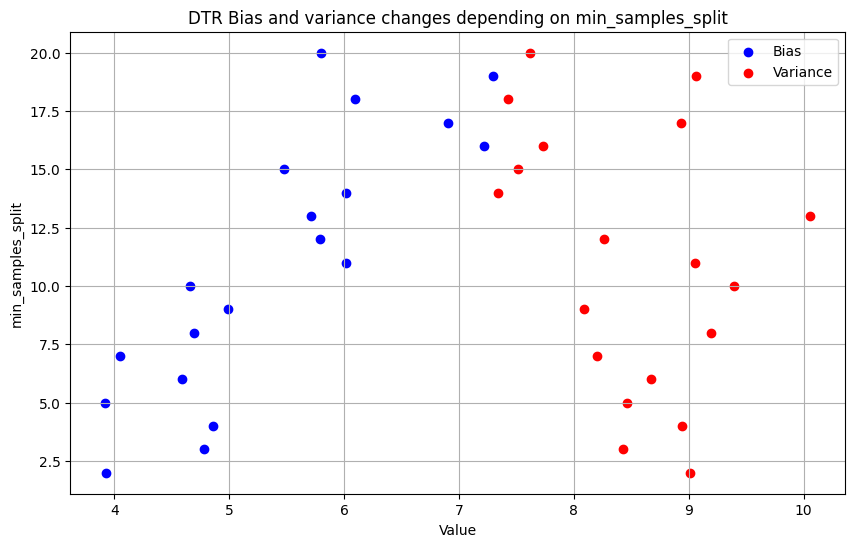

In [ ]:
splits = np.arange(2, 21)
bs = []
vars = []
for split in splits:
    est = MyDecisionTreeRegressor(max_depth=8, min_samples_split = split)
    bias, variance = get_bias_variance(est, X_train.values, y_train, 10)
    bs.append(bias)
    vars.append(variance)
plt.figure(figsize=(10, 6))
plt.scatter(bs, splits, color='blue', label='Bias')
plt.scatter(vars, splits, color='red', label='Variance')
plt.title(f'DTR Bias and variance changes depending on min_samples_split')
plt.xlabel('Value')
plt.ylabel('min_samples_split')
plt.legend()
plt.grid()
plt.show()

``` your comments here```
It seems like there is a lineal dependence in BIAS, and some chaotic thing in VARIANCE. However, i think it's better not to take a large value for min samples split in order to reduce BIAS, but it may work with VARIANCE.

### Task 8 <a id="task8"></a>  (0.5 points)

Let's try to reduce variance with bagging. Use `sklearn.ensemble.BaggingRegressor` to get an ensemble and compute its bias and variance.

Answer the following questions:
 - How bagging should affect bias and variance in theory?
 - How bias and variance change (if they change) compared to an individual tree in you experiments?
 - Do your results align with the theory? Why?

Bagging should decrease variance, but may slightly increase Bias.

In [ ]:
from sklearn.ensemble import BaggingRegressor
bagging_model = BaggingRegressor(MyDecisionTreeRegressor(), n_estimators=50)
bagging_bias, bagging_variance =get_bias_variance(bagging_model, X_train.values, y_train, 10)
print(f"Bagging Bias^2: {bagging_bias}, Bagging Variance: {bagging_variance}")

Bagging Bias^2: 14.610163849029755, Bagging Variance: 2.359137173130799


Variance was GREATLY DECREASED!
However, bias has increased approximately by 3 times... It may happened due to the complexity of the tree(depths), or problems with data, but main goal was achieved!

In [ ]:
bagging_model = BaggingRegressor(DecisionTreeRegressor(), n_estimators=50)
bagging_bias, bagging_variance =get_bias_variance(bagging_model, X_train.values, y_train, 10)
print(f"Bagging Bias^2: {bagging_bias}, Bagging Variance: {bagging_variance}")

Bagging Bias^2: 3.937267032506597, Bagging Variance: 2.7144571416358847


As we can see, using sklearn model has different results. Variance is bigger than in prevous try, but Bias DECREASED AS WELL.

In [ ]:
bagging_model = BaggingRegressor(DecisionTreeRegressor(max_depth = 10), n_estimators=50) # max_depth = 10 is better
bagging_bias, bagging_variance =get_bias_variance(bagging_model, X_train.values, y_train, 10)
print(f"Bagging Bias^2: {bagging_bias}, Bagging Variance: {bagging_variance}")

Bagging Bias^2: 3.902813118407485, Bagging Variance: 2.56128263479624


In [ ]:
bagging_model = BaggingRegressor(MyDecisionTreeRegressor(max_depth = 10), n_estimators=50)
bagging_bias, bagging_variance =get_bias_variance(bagging_model, X_train.values, y_train, 10)
print(f"Bagging Bias^2: {bagging_bias}, Bagging Variance: {bagging_variance}")

Bagging Bias^2: 3.8289698699603285, Bagging Variance: 2.6034115663462756


Now its perfect with max_depth = 10;

# Part 2. More Ensembles

In this part we will be working with [Billionaires Statistics Dataset](https://www.kaggle.com/datasets/nelgiriyewithana/billionaires-statistics-dataset) to solve a classification task.

In [ ]:
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv('Billionaires Statistics Dataset.csv')

le = LabelEncoder()
y = le.fit_transform(df['selfMade'])
X = df.drop('selfMade', axis=1)
X.head(10)

,rank,finalWorth,category,personName,age,country,city,source,industries,countryOfCitizenship,...,cpi_change_country,gdp_country,gross_tertiary_education_enrollment,gross_primary_education_enrollment_country,life_expectancy_country,tax_revenue_country_country,total_tax_rate_country,population_country,latitude_country,longitude_country
0,1,211000,Fashion & Retail,Bernard Arnault & family,74.0,France,Paris,LVMH,Fashion & Retail,France,...,1.1,"$2,715,518,274,227",65.6,102.5,82.5,24.2,60.7,6.705989e+07,46.227638,2.213749
1,2,180000,Automotive,Elon Musk,51.0,United States,Austin,"Tesla, SpaceX",Automotive,United States,...,7.5,"$21,427,700,000,000",88.2,101.8,78.5,9.6,36.6,3.282395e+08,37.090240,-95.712891
2,3,114000,Technology,Jeff Bezos,59.0,United States,Medina,Amazon,Technology,United States,...,7.5,"$21,427,700,000,000",88.2,101.8,78.5,9.6,36.6,3.282395e+08,37.090240,-95.712891
3,4,107000,Technology,Larry Ellison,78.0,United States,Lanai,Oracle,Technology,United States,...,7.5,"$21,427,700,000,000",88.2,101.8,78.5,9.6,36.6,3.282395e+08,37.090240,-95.712891
4,5,106000,Finance & Investments,Warren Buffett,92.0,United States,Omaha,Berkshire Hathaway,Finance & Investments,United States,...,7.5,"$21,427,700,000,000",88.2,101.8,78.5,9.6,36.6,3.282395e+08,37.090240,-95.712891
5,6,104000,Technology,Bill Gates,67.0,United States,Medina,Microsoft,Technology,United States,...,7.5,"$21,427,700,000,000",88.2,101.8,78.5,9.6,36.6,3.282395e+08,37.090240,-95.712891
6,7,94500,Media & Entertainment,Michael Bloomberg,81.0,United States,New York,Bloomberg LP,Media & Entertainment,United States,...,7.5,"$21,427,700,000,000",88.2,101.8,78.5,9.6,36.6,3.282395e+08,37.090240,-95.712891
7,8,93000,Telecom,Carlos Slim Helu & family,83.0,Mexico,Mexico City,Telecom,Telecom,Mexico,...,3.6,"$1,258,286,717,125",40.2,105.8,75.0,13.1,55.1,1.260140e+08,23.634501,-102.552784
8,9,83400,Diversified,Mukesh Ambani,65.0,India,Mumbai,Diversified,Diversified,India,...,7.7,"$2,611,000,000,000",28.1,113.0,69.4,11.2,49.7,1.366418e+09,20.593684,78.962880
9,10,80700,Technology,Steve Ballmer,67.0,United States,Hunts Point,Microsoft,Technology,United States,...,7.5,"$21,427,700,000,000",88.2,101.8,78.5,9.6,36.6,3.282395e+08,37.090240,-95.712891


### Task 1 <a id="task2_1"></a> (1 point)

Let's start with data preprocessing.

0. Drop columns, which are not usefull (e.g. a lot of missing values). Motivate your choice.
1. Split dataset into train and test
2. You've probably noticed that we have both categorical and numerical columns. Here is what you need to do with them:
    - Categorical: Fill missing values and apply one-hot-encoding (if there are more than 10 unique values in a column, use `min_frequency` and/or `max_categories` parameter)
    - Numeric: Fill missing values
    
Use `ColumnTranformer` to define a single transformer for all the columns in the dataset. It takes as input a list of tuples

```
ColumnTransformer([
    ('name1', transform1, column_names1),
    ('name2', transform2, column_names2)
])
```

Pay attention to an argument `remainder='passthrough'`. [Here](https://scikit-learn.org/stable/modules/compose.html#column-transformer) you can find some examples of how to use column transformer.
    
Since we want to apply 2 transformations to categorical feature, it is very convenient to combine them into a `Pipeline`:

```
double_tranform = make_pipeline(
                        transform_1,
                        transform_2
                        )
```

P.S. Choose your favourite way to fill missing values.

*Hint* Categorical column usually have `dtype = 'object'`. This may help to obtain list of categorical and numerical columns on the dataset.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer



missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])# Display columns with missing values
cols_to_drop = ['birthDate', 'lastName', 'firstName', 'organization', 'title']
df.drop(cols_to_drop, axis=1, inplace=True)

age                                             65
country                                         38
city                                            72
organization                                  2315
birthDate                                       76
firstName                                        3
title                                         2301
state                                         1887
residenceStateRegion                          1893
birthYear                                       76
birthMonth                                      76
birthDay                                        76
cpi_country                                    184
cpi_change_country                             184
gdp_country                                    164
gross_tertiary_education_enrollment            182
gross_primary_education_enrollment_country     181
life_expectancy_country                        182
tax_revenue_country_country                    183
total_tax_rate_country         

**I decided to drop title and organization columns, and it has given the better result comparing with including these features**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(exclude=['object']).columns.tolist()

categorical_transformer = make_pipeline(
    SimpleImputer(strategy='most_frequent'),  # Fill missing values with the most frequent value
    OneHotEncoder(handle_unknown='ignore')
)

# Numerical transformer: fill missing values and scale
numerical_transformer = make_pipeline(
    SimpleImputer(strategy='mean'),             # Fill missing values with the mean
    StandardScaler()
)

column_transformer = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, categorical_cols),
        ('num', numerical_transformer, numerical_cols)
    ],
    remainder='passthrough'
)

# Transform the data
X_train = column_transformer.fit_transform(X_train)
X_test = column_transformer.transform(X_test)

### Task 2 <a id="task2_2"></a> (0.7 points)

Fit and compare 5 different models (use sklearn): Gradient Boosting, Random Forest, Decision Tree, SVM, Logitics Regression
    
* Choose one classification metric and justify your choice .
* Compare the models using score on cross validation. Mind the class balance when choosing the cross validation. (You can read more about different CV strategies [here](https://scikit-learn.org/stable/modules/cross_validation.html#stratified-k-fold))
* Which model has the best performance? Which models overfit or underfit?

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

In [ ]:
models = {
    'Gradient Boosting': GradientBoostingClassifier(),
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'SVM': SVC(probability=True),
    'Logistic Regression': LogisticRegression(max_iter=1000)
}

# Set up stratified K-Folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


In [ ]:
results = {}

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1')
    results[name] = scores
    print(f"{name}: Mean F1 Score = {np.mean(scores):.4f}, Std Dev = {np.std(scores):.4f}")

Gradient Boosting: Mean F1 Score = 0.8632, Std Dev = 0.0133
Random Forest: Mean F1 Score = 0.8624, Std Dev = 0.0071
Decision Tree: Mean F1 Score = 0.8289, Std Dev = 0.0104
SVM: Mean F1 Score = 0.8597, Std Dev = 0.0102
Logistic Regression: Mean F1 Score = 0.8592, Std Dev = 0.0127


In [ ]:
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    test_f1_score = f1_score(y_test, y_pred)
    print(f"{name}: Test F1 Score: {test_f1_score:.4f}")

Gradient Boosting: Test F1 Score: 0.8688
Random Forest: Test F1 Score: 0.8726
Decision Tree: Test F1 Score: 0.8354
SVM: Test F1 Score: 0.8643
Logistic Regression: Test F1 Score: 0.8673


The best model according to F1 score was **RANDOM FOREST**, The worst model was **Decisison Tree***, but the difference between model metrics isn't that much.
Decision Tree model may be overfit, but all of them seems to be OK.

**UPD: DROPED SOME EXTRA FEATURES(with a large number of missing values), so the results of Decision Tree became better, so i don't see overfit or underfit here.**

### Task 3 <a id="task2_3"></a> (0.5 points)

More Gradient Boosting. You will have to take one of the three popular boosting implementations (xgboost, lightgbm, catboost). Select hyperparameters (number of trees, learning rate, depth) on cross-validation and compare with the methods from the previous task.

In [ ]:
# я устал, я ухожу с ютуба.

```your comments here```

### Task 4 <a id="task2_4"></a> (0.7 points)

Now let's train more fancy ensembles:

* Bagging with decision trees as base estimators
* Bagging with gradient boosting (with large amount of trees, >100) as base estimators
* [Voting classifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html#sklearn.ensemble.VotingClassifier)
* [Stacking Classifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html#sklearn.ensemble.StackingClassifier) with Logistic Regression as a final model
* [Stacking Classifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html#sklearn.ensemble.StackingClassifier) with Gradeint Boosting as a final model


If not stated in the task, feel free to tune / choose hyperparameters and base models.

Answer the questions:
* Which model has the best performance?
* Does bagging reduce overfiting of the gradient boosting with large amount of trees?
* What is the difference between voting and staking?

In [ ]:
# YOUR CODE HERE

```your comments here```

### Task 5 <a id="task2_5"></a> (0.1 points)

Report the test score for the best model, that you were able to train.

In [ ]:
# YOUR CODE HERE